In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from datetime import timedelta
from numpy.ma.core import count, append
%matplotlib inline

## 1. Подготовка данных

In [2]:
#Путь к нашим данным.
ad1 = "data/Заказ_ID.csv"
ad2 = "data/Клиент_ID.csv"
ad3 = "data/Продукты_ID.csv"
ad4 = "data/Заказ_Доп_ID.csv"

order = pd.read_csv(ad1, sep=';', encoding='cp1251')
customers = pd.read_csv(ad2, sep=';', encoding='cp1251')
products = pd.read_csv(ad3, sep=';', encoding='cp1251')
order_it = pd.read_csv(ad4, sep=';', encoding='cp1251')



display(order.head())
display(customers.head())
display(products.head())
display(order_it.head())

,order_id,customer_id,order_date,total_amount
0,1,3,05.01.2023,1500
1,2,7,12.01.2023,6000
2,3,12,18.01.2023,20000
3,4,5,22.01.2023,1000
4,5,19,28.01.2023,50000


,customer_id,name,email,join_date
0,1,Иван Петров,ivan.petrov@mail.ru,15.01.2022
1,2,Елена Смирнова,elena.smirnova@gmail.com,20.02.2022
2,3,Алексей Иванов,alex.ivanov@yandex.ru,10.03.2022
3,4,Ольга Кузнецова,olga.kuz@mail.ru,05.04.2022
4,5,Дмитрий Соколов,dima.sokolov@gmail.com,12.05.2022


,product_id,product_name,price,category
0,1,Ноутбук,50000,Электроника
1,2,Смартфон,30000,Электроника
2,3,Футболка,1000,Одежда
3,4,Кроссовки,4000,Обувь
4,5,Чайник,2000,Бытовая техника


,order_item_id,order_id,product_id,quantity
0,1,1,9,1
1,2,2,16,2
2,3,3,19,1
3,4,4,3,1
4,5,5,1,1


# **2.Анализ продаж**

## График общего количества заказов по месяцам

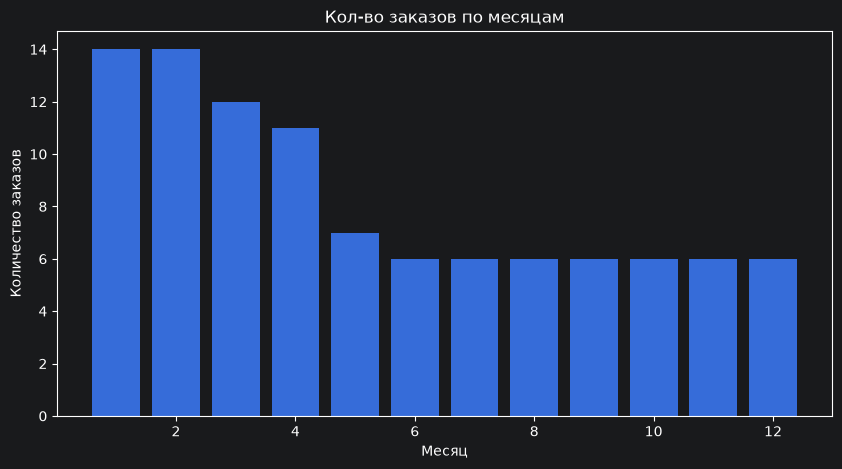

In [3]:
order['order_date'] = pd.to_datetime(order['order_date'], dayfirst=True)
order['month'] = order['order_date'].dt.month

month = order['month'].drop_duplicates().to_numpy()
month_count = order['month'].value_counts()

plt.figure(figsize=(10, 5))
plt.title('Кол-во заказов по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество заказов')
plt.bar(month, month_count)
plt.show()

## Средняя сумма заказа и график её изменения по месяцам

<BarContainer object of 100 artists>

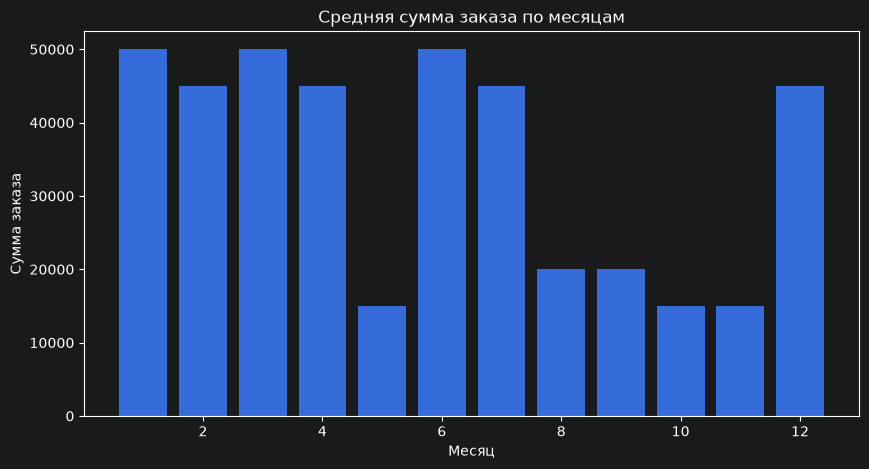

In [4]:
amount_month = pd.DataFrame({'month': order['month'],'total_amount': order['total_amount'], 'quantity': order_it['quantity']})

# Находим среднюю сумму
amount_month['sr'] = round(amount_month['total_amount']/amount_month['quantity'],2)

plt.figure(figsize=(10, 5))
plt.title('Средняя сумма заказа по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Сумма заказа')
plt.bar(amount_month["month"], amount_month['sr'])

## Анализ динамики новых клиентов

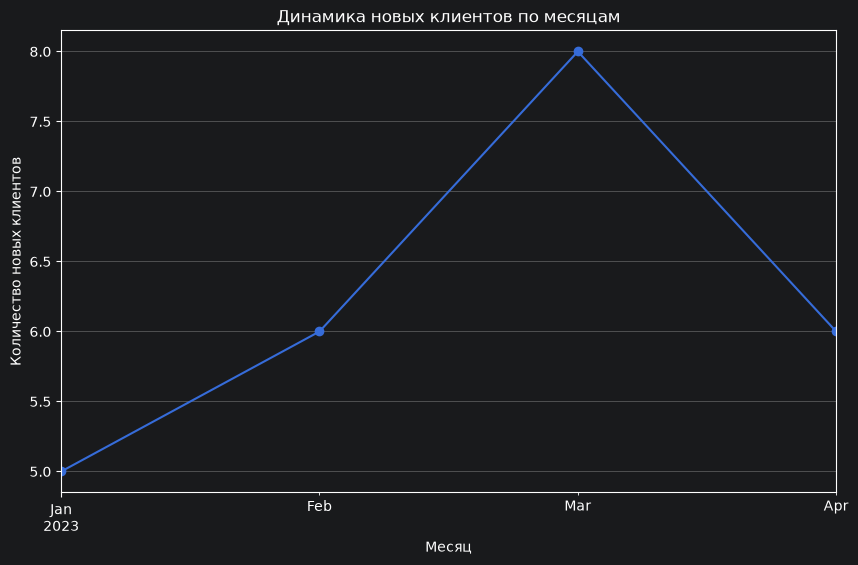

In [5]:
# Добавим столбец с месяцем первого заказа
first_orders = order.groupby('customer_id')['order_date'].min().reset_index()
first_orders['first_order_month'] = first_orders['order_date'].dt.to_period('M')

# Посчитаем количество новых клиентов по месяцам
new_customers_by_month = first_orders.groupby('first_order_month').size()

# Построим график
plt.figure(figsize=(10,6))
new_customers_by_month.plot(marker='o')
plt.ylabel('Количество новых клиентов')
plt.xlabel('Месяц')
plt.title('Динамика новых клиентов по месяцам')
plt.grid(True)
plt.show()


# **3. Товарный анализ и ассортимент**

## Топ-5 продуктов по количеству продаж и визуализация результатов

,product_name,quantity
0,Телевизор,8
1,Часы,8
2,Кофемашина,7
3,Стол,7
4,Рубашка,6


<Axes: title={'center': 'Топ-5 продуктов'}, xlabel='Продукты', ylabel='Кол-во'>

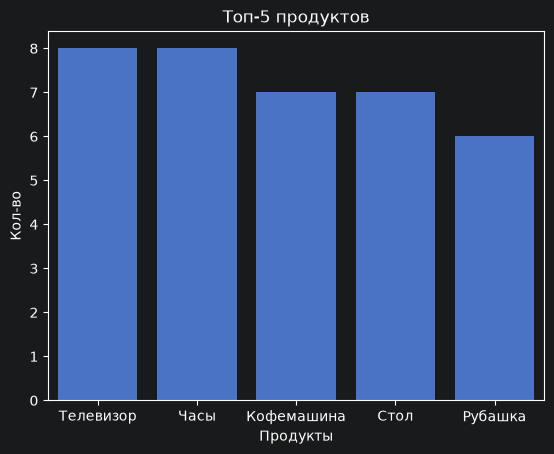

In [6]:
rez_product = order_it.groupby("product_id", as_index=False)['quantity'].sum().sort_values('quantity', ascending=False).head(5)
rez_product = pd.merge(rez_product, products, on='product_id', how='left')[['product_name', 'quantity']]

display(rez_product)

plt.title('Топ-5 продуктов')
plt.xlabel('Продукты')
plt.ylabel('Кол-во')
sns.barplot( data = rez_product, x ='product_name', y ='quantity')

## Анализ среднего чека по категориям продуктов

Text(0.5, 1.0, 'Средний чек заказа по категориям продуктов')

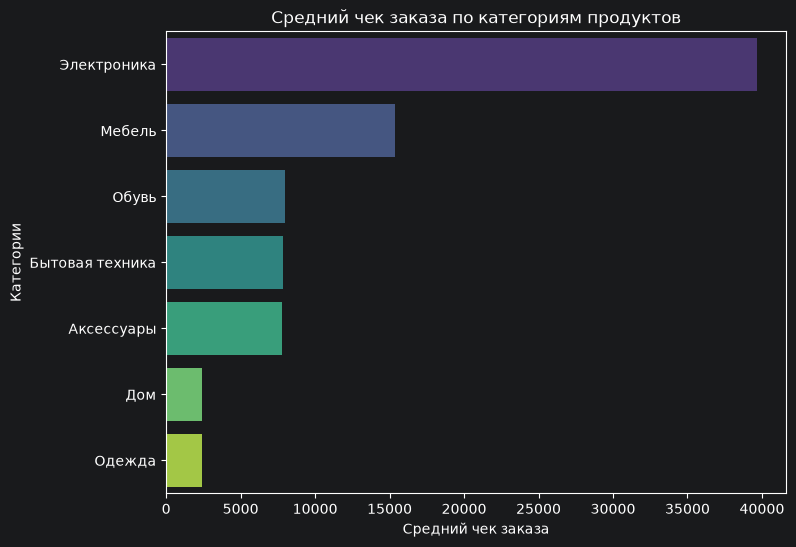

In [7]:
# Объединим order_items с products
order_items_with_products = pd.merge(order_it, products, on='product_id')

# Объединим с заказами, чтобы получить дату и сумму заказа
order_items_full = pd.merge(order_items_with_products, order[['order_id', 'order_date', 'total_amount']], on='order_id')

# Для каждой категории найдем средний чек
category_avg_check = order_items_full.groupby('category')['total_amount'].mean().sort_values(ascending=False)

# Построим диаграмму
plt.figure(figsize=(8,6))
sns.barplot(
    x=category_avg_check.values,
    y=category_avg_check.index,
    hue=category_avg_check.index,
    palette='viridis',
    legend=False
)
plt.xlabel('Средний чек заказа')
plt.ylabel('Категории')
plt.title('Средний чек заказа по категориям продуктов')

## Анализ категорий продуктов
Общая сумма продаж для по категории продуктов и круговая диаграмма

In [8]:
import plotly.express as px
product_sum = order_it.groupby("product_id", as_index=False)['quantity'].sum()

# Добовляем поля из таблицы Продукты
product_margin = products[["product_id", "price", "category"]]
product_sum = product_sum.merge(product_margin, on="product_id", how="left")

# Находим цену товаров с учетом кол-ва заказаного товара
product_sum["цена"] = product_sum["price"] * product_sum["quantity"]

# Удаление строки product_id quantity price
del product_sum["price"],product_sum["quantity"], product_sum["product_id"]

# Находим сумму с учетом категории
product_sum = product_sum.groupby("category", as_index=False)['цена'].sum()
display("сумма с учетом категории", product_sum)

# Строим диаграмму
fig = px.pie(product_sum, values='цена', names='category', hole=0.3,
    width=400, height=400)
fig.update_traces(textinfo='percent', textfont_size=14,
    textfont_color='white', marker=dict(line=dict(color='white', width=2)))
fig.show()


'сумма с учетом категории'

,category,цена
0,Аксессуары,78000
1,Бытовая техника,226500
2,Дом,36300
3,Мебель,230000
4,Обувь,16000
5,Одежда,36000
6,Электроника,555000


# **4. Анализ клиентов и поведенческая сегментация**

## Анализ уникальных клиентов
Количество уникальных клиентов, сделавших хотя бы один заказ

In [9]:
customers_values = customers[customers['customer_id'].isin(order['customer_id'])]
print("Количество уникальных клиентов, сделавших хотя бы один заказ")
print("Количество клиентов:", customers['customer_id'].count())
print("Количество клиентов, сделавших заказ: ", customers_values['customer_id'].count())

Количество уникальных клиентов, сделавших хотя бы один заказ
Количество клиентов: 25
Количество клиентов, сделавших заказ:  25


## График распределения клиентов по количеству заказов

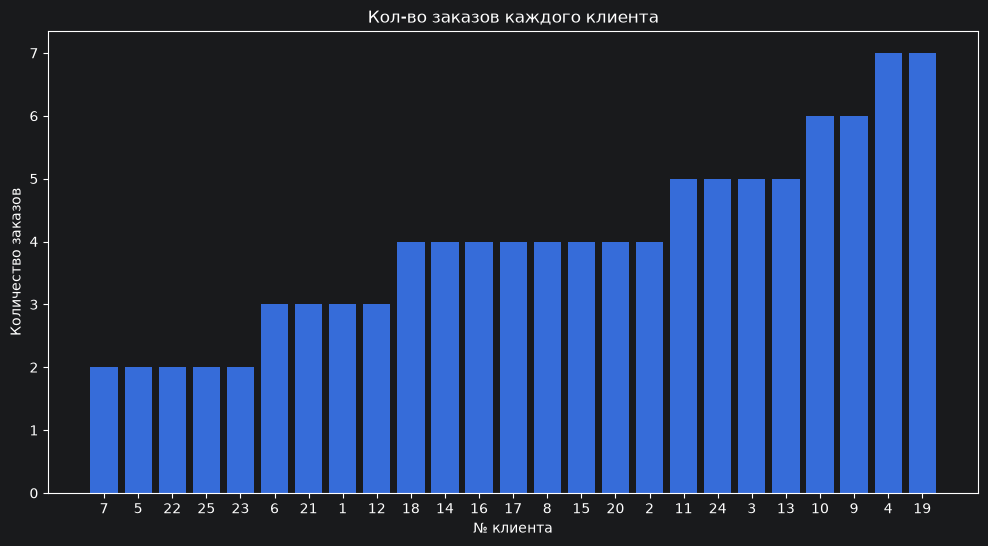

In [10]:
orders_per_customer = order['customer_id'].value_counts().sort_values(ascending=True)
plt.figure(figsize=(12, 6))
plt.title('Кол-во заказов каждого клиента')
plt.xlabel('№ клиента')
plt.ylabel('Количество заказов')
plt.bar(orders_per_customer.index.astype(str), orders_per_customer.values)
plt.show()

## Топ-5 клиентов по общей сумме покупок

<Axes: title={'center': 'Топ-5 клиентов'}, xlabel='№ клиента', ylabel='Сумма заказов'>

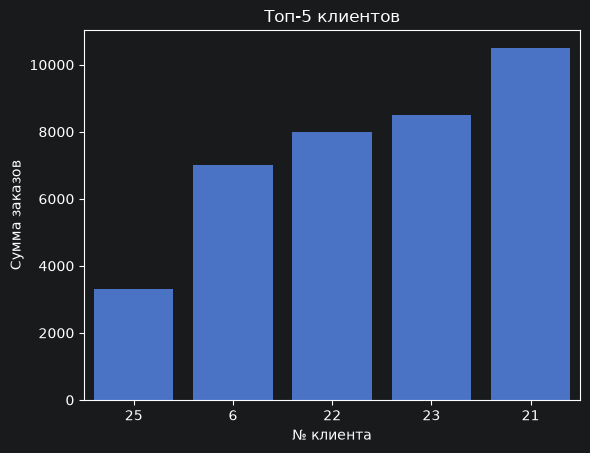

In [11]:
# Отбираем 5 клиентов по общей сумме покупок
rez_customers_sum = order.groupby("customer_id", as_index=False)['total_amount'].sum().sort_values('total_amount', ascending=True).head(5)
rez_customers_sum['customer_id'] = rez_customers_sum['customer_id'].astype(str)
plt.title('Топ-5 клиентов')
plt.xlabel('№ клиента')
plt.ylabel('Сумма заказов')
sns.barplot( data=rez_customers_sum, x='customer_id', y='total_amount')

## RFM-анализ

In [12]:
# Определяем день после последнего заказа
analysis_date = order['order_date'].max() + timedelta(days=1)

# Группируем по клиенту и вычисляем R, F, M
rfm = order.groupby('customer_id').agg({
    'order_date': lambda x: (analysis_date - x.max()).days,
    'order_id': 'nunique',
    'total_amount': 'sum'
}).reset_index()
rfm.columns = ['customer_id', 'Recency', 'Frequency', 'Monetary']
rfm.columns = ['customer_id', 'Recency', 'Frequency', 'Monetary']

# Присваиваем баллы R, F, M на основе квантилей
rfm['R_score'] = pd.qcut(rfm['Recency'], 5, labels=[5,4,3,2,1])
rfm['F_score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1,2,3,4,5])
rfm['M_score'] = pd.qcut(rfm['Monetary'], 5, labels=[1,2,3,4,5])

# Формируем сегмент и общий RFM-скоро
rfm['RFM_Segment'] = rfm['R_score'].astype(str) + rfm['F_score'].astype(str) + rfm['M_score'].astype(str)
rfm['RFM_Score'] = rfm[['R_score', 'F_score', 'M_score']].astype(int).sum(axis=1)

# Визуализация топ сегментов
print(rfm.sort_values('RFM_Score' ,ascending=False).head(10))

    customer_id  Recency  Frequency  Monetary R_score F_score M_score  \
8             9       31          6     85000       4       5       4   
19           20        1          4     77000       5       4       4   
23           24       66          5    117000       3       5       5   
9            10       71          6     88000       3       5       5   
3             4      141          7    114500       2       5       5   
18           19      121          7    115000       2       5       5   
2             3       21          5     28000       5       4       3   
13           14        6          4     31800       5       3       3   
17           18       36          4     32300       4       4       3   
14           15       26          4     71500       4       3       4   

   RFM_Segment  RFM_Score  
8          454         13  
19         544         13  
23         355         13  
9          355         13  
3          255         12  
18         255         12  


# **5. Анализ лояльности, удержания и жизненного цикла**

## Расчет метрик лояльности

Доля клиентов, сделавших более одного заказа: 100.00%
Среднее количество заказов на клиента: 4.00


Text(0, 0.5, 'Число клиентов')

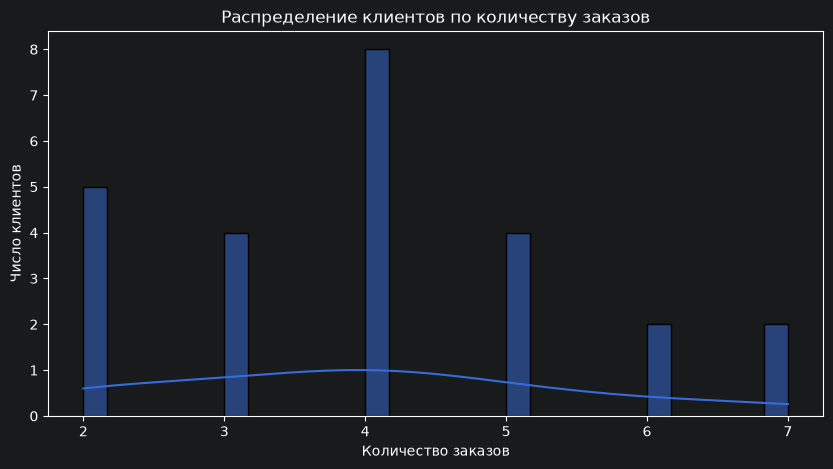

In [13]:
# Количество повторных покупок на клиента
customer_order = order.groupby('customer_id')['order_id'].count().reset_index()
customer_order.columns = ['customer_id', 'total_orders']

# Доля клиентов, сделавших более одного заказа
repeat_customers = customer_order[customer_order['total_orders'] > 1].shape[0]
total_customers = customer_order.shape[0]
repeat_purchase_rate = repeat_customers / total_customers
print(f'Доля клиентов, сделавших более одного заказа: {repeat_purchase_rate:.2%}')

# Среднее количество заказов на клиента
aof = customer_order['total_orders'].mean()
print(f'Среднее количество заказов на клиента: {aof:.2f}')

# Гистограмма
plt.figure(figsize=(10, 5))
sns.histplot(data=customer_order, x='total_orders', bins=30, kde=True)
plt.title('Распределение клиентов по количеству заказов')
plt.xlabel('Количество заказов')
plt.ylabel('Число клиентов')

## Коэффициент удержания

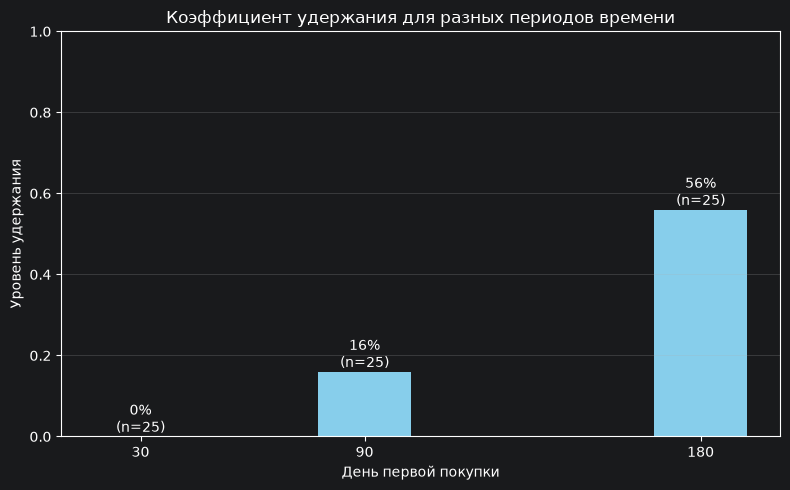

In [14]:
# Рассчитываем "возраст" клиента (сколько дней прошло с первой покупки до последней даты в данных)
last_date = order['order_date'].max()
order['first_purchase'] = order.groupby('customer_id')['order_date'].transform('min')
order['days_since_first'] = (order['order_date'] - order['first_purchase']).dt.days
order['cohort_age'] = (last_date - order['first_purchase']).dt.days

# Параметры анализа
days = [30, 90, 180]
results = []

for d in days:
    # Выбираем только клиентов, у которых было достаточно времени для возврата
    eligible_clients = order[order['cohort_age'] >= d]['customer_id'].unique()

    # Фильтруем заказы для этих клиентов в период [0, d] дней
    period_orders = order[(order['customer_id'].isin(eligible_clients)) &
     (order['days_since_first'] <= d)]

    # Считаем клиентов с повторными покупками (≥2 заказов в период)
    repeat_counts = period_orders.groupby('customer_id').size()
    retained_clients = repeat_counts[repeat_counts >= 2].index.nunique()
    retention_rate = retained_clients / len(eligible_clients) if len(eligible_clients) > 0 else 0
    results.append({'days': d, 'rate': retention_rate, 'n': len(eligible_clients)})

# Создаем DataFrame с результатами
ret_df = pd.DataFrame(results)

# Визуализация с указанием размера выборки
plt.figure(figsize=(8, 5))
bars = plt.bar(ret_df['days'], ret_df['rate'], width=25, color='skyblue')

# Добавляем подписи с размером выборки
for bar, n in zip(bars, ret_df['n']):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height, f'{height:.0%}\n(n={n})', ha='center', va='bottom')

plt.title('Коэффициент удержания для разных периодов времени')
plt.xlabel('День первой покупки')
plt.ylabel('Уровень удержания')
plt.xticks(days)
plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

## Анализ времени до повторной покупки

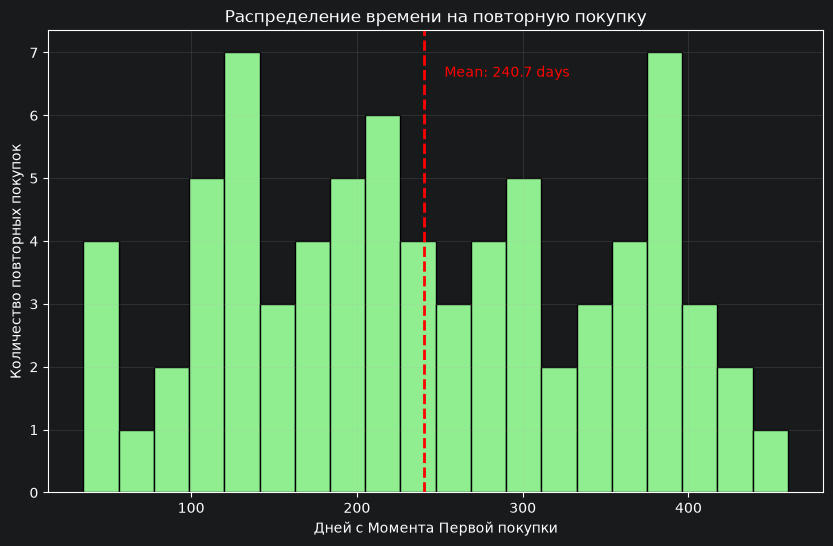

In [15]:
repeat_purchases = order[order['days_since_first'] > 0].copy()

if not repeat_purchases.empty:
    plt.figure(figsize=(10, 6))
    plt.hist(repeat_purchases['days_since_first'], bins=20, color='lightgreen', edgecolor='black')
    plt.axvline(repeat_purchases['days_since_first'].mean(), color='red',  linestyle='dashed',
                linewidth=2)
    plt.text(repeat_purchases['days_since_first'].mean()*1.05, plt.ylim()[1]*0.9,
             f'Mean: {repeat_purchases["days_since_first"].mean():.1f} days', color='red')
    plt.title('Распределение времени на повторную покупку')
    plt.xlabel('Дней с Момента Первой покупки')
    plt.ylabel('Количество повторных покупок')
    plt.grid(alpha=0.2)
    plt.show()
else:
    print("Повторных покупок не обнаружено")

# **6. Ценовой анализ и ценовая чувствительность**

## Подготовка данных

In [16]:
sales_data = pd.merge(order_it, products, on='product_id')
sales_data = pd.merge(sales_data, order, on='order_id')

# Фильтрация и агрегация
sales_data = sales_data[sales_data['quantity'] > 0]
product_stats = sales_data.groupby('product_id').agg( product_name=('product_name', 'first'),
    category=('category', 'first'), price=('price', 'mean'), total_sold=('quantity', 'sum'),
    num_orders=('order_id', 'nunique')).reset_index()


## Распределение цен и продаж

Text(0, 0.5, 'Количество продаж')

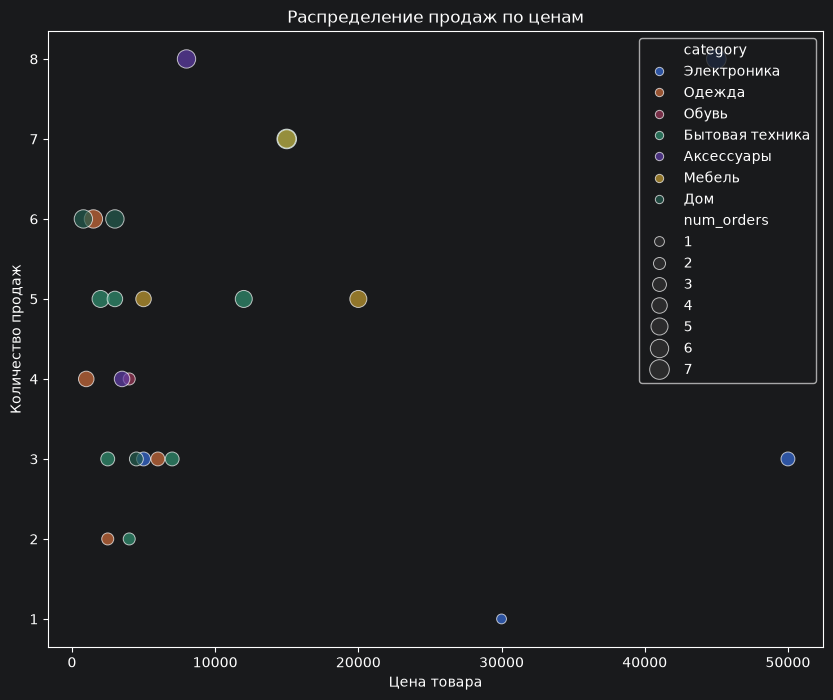

In [17]:
plt.figure(figsize=(10, 8))
sns.scatterplot(data=product_stats, x='price', y='total_sold', hue='category', size='num_orders',
    sizes=(50, 200), alpha=0.7)
plt.title('Распределение продаж по ценам')
plt.xlabel('Цена товара')
plt.ylabel('Количество продаж')

## Распределение цен по категориям

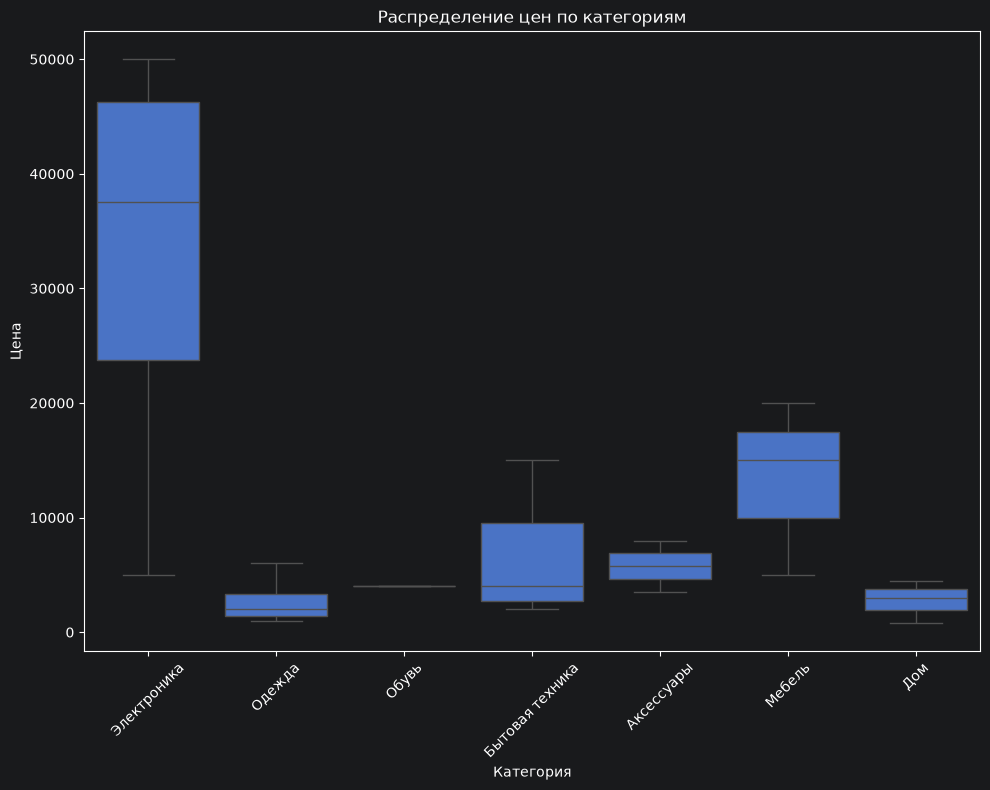

In [18]:
plt.figure(figsize=(10, 8))
sns.boxplot(data=product_stats, x='category', y='price', showfliers=False)
plt.title('Распределение цен по категориям')
plt.xlabel('Категория')
plt.ylabel('Цена')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Зависимость количества заказов от цены

Text(0, 0.5, 'Количество заказов')

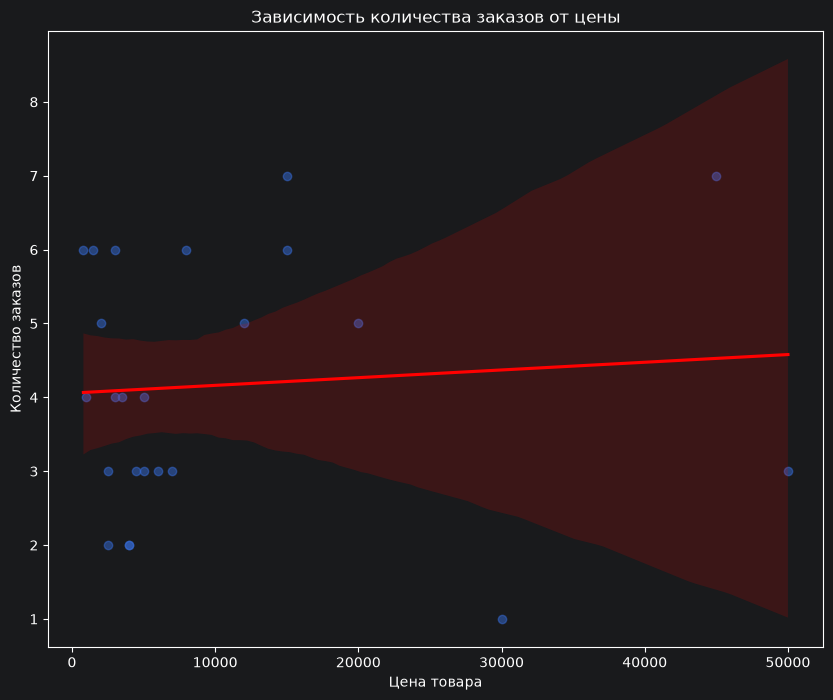

In [19]:
plt.figure(figsize=(10, 8))
sns.regplot(data=product_stats, x='price', y='num_orders', scatter_kws={'alpha':0.5},
    line_kws={'color':'red'})
plt.title('Зависимость количества заказов от цены')
plt.xlabel('Цена товара')
plt.ylabel('Количество заказов')

## Корреляция цена-продажи по категориям и рекомендация по ценообразованию

In [20]:
category_stats = product_stats.groupby('category').filter(lambda x: len(x) > 1)

if not category_stats.empty:
    # Расчет корреляции цены и продаж внутри категорий
    category_corrs = category_stats.groupby('category').apply(
        lambda g: g['price'].corr(g['total_sold'], method='spearman')).dropna()

    if not category_corrs.empty:
        print("\nКорреляция цена-продажи по категориям:")
        print(category_corrs.sort_values())
    else:
        print("Недостаточно данных для расчета корреляции по категориям")
else:
    print("Недостаточно товаров для анализа по категориям (нужно >1 товара в категории)")

# Рекомендации по ценообразованию
print("\nРекомендации по ценообразованию:")
for idx, row in product_stats.iterrows():
    price_rank = (product_stats['price'] < row['price']).mean()
    sales_rank = (product_stats['total_sold'] > row['total_sold']).mean()

    if sales_rank < 0.3 and price_rank > 0.7:
        rec = ">> Снизить цену (высокая цена, низкие продажи)"
    elif sales_rank > 0.7 and price_rank < 0.3:
        rec = ">> Повысить цену (низкая цена, высокие продажи)"
    else:
        rec = ">> Оставить цену без изменений"
    print(f"{row['product_name']} ({row['category']}): {rec}")


Корреляция цена-продажи по категориям:
category
Дом               -0.866025
Одежда            -0.600000
Мебель             0.000000
Электроника        0.316228
Бытовая техника    0.318105
Аксессуары         1.000000
dtype: float64

Рекомендации по ценообразованию:
Ноутбук (Электроника): >> Оставить цену без изменений
Смартфон (Электроника): >> Оставить цену без изменений
Футболка (Одежда): >> Оставить цену без изменений
Кроссовки (Обувь): >> Оставить цену без изменений
Чайник (Бытовая техника): >> Оставить цену без изменений
Телевизор (Электроника): >> Снизить цену (высокая цена, низкие продажи)
Наушники (Электроника): >> Оставить цену без изменений
Джинсы (Одежда): >> Повысить цену (низкая цена, высокие продажи)
Рубашка (Одежда): >> Оставить цену без изменений
Куртка (Одежда): >> Оставить цену без изменений
Сумка (Аксессуары): >> Оставить цену без изменений
Часы (Аксессуары): >> Оставить цену без изменений
Кофемашина (Бытовая техника): >> Снизить цену (высокая цена, низкие продажи)
М

# **7. Временной анализ и сезонность**

## Анализ по дням недели

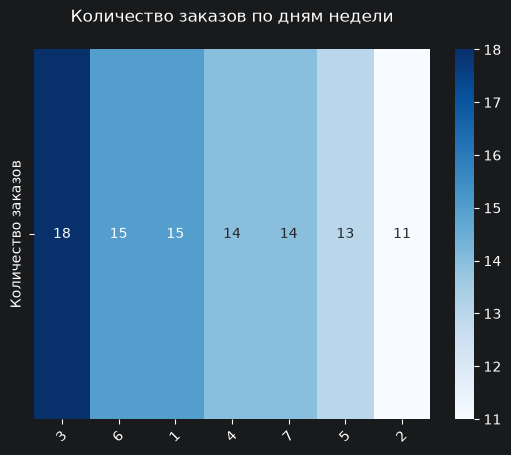

In [21]:
# Заказы по дням недели
# Добавляем столбец с днём недели (0=понедельник, 6=воскресенье)
order["week"] = order["order_date"].dt.weekday
order["week"] = order["week"] + 1

ct_week = order['week'].value_counts()
week = ct_week.reset_index()
week.columns = ['День недели', 'Заказов']

sns.heatmap(week[['Заказов']].T, annot=True, fmt="d", cmap="Blues",
            yticklabels=['Количество заказов'], xticklabels=week['День недели'])
plt.title("Количество заказов по дням недели", pad=20)
plt.xticks(rotation=45)
plt.show()

## Анализ по месяцам

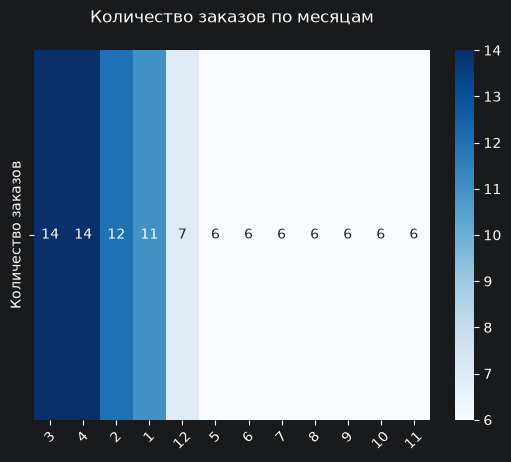

In [22]:
ct_mouth = order['month'].value_counts()
month = ct_mouth.reset_index()
month.columns = ['Месяц', 'Заказов']

sns.heatmap(month[['Заказов']].T, annot=True, fmt="d", cmap="Blues",
            yticklabels=['Количество заказов'], xticklabels=month['Месяц'])
plt.title("Количество заказов по месяцам", pad=20)
plt.xticks(rotation=45)
plt.show()